In [1]:
from rdkit import DataStructs, Chem
from rdkit.Chem import PandasTools, AllChem
from rdkit.Chem.rdMolDescriptors import GetMorganFingerprint
from pathlib import Path
from joblib import Parallel, delayed
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import seaborn as sns
import msoffcrypto, io
import re, multiprocessing, sys, platform

In [2]:
if platform.system() == "Windows":
    dropbox_dir = Path.home() / "Serac Biosciences Dropbox"
    utils_dir = dropbox_dir / "Serac_team" / "4_Data_Sciences" / "4_Method_Development"
else:  # Linux / WSL2
    dropbox_dir = Path("/mnt/c/Users") / Path.home().name / "Serac Biosciences Dropbox"
    utils_dir = dropbox_dir / "Florent Chevillard" / "Documents" / "scripts"

In [3]:
sys.path.insert(0, str(utils_dir))
import utils
from utils.chem.fingerprints import get_ecfp4_from_mol
from utils.chem.standardization import standardize_smiles, get_mol_from_smi
from utils.chem.diversity import compute_tsne_ecfp4
from utils.data.dataframe_operations import apply_in_parallel

<div style="background-color: #d4edda; padding: 10px; border-radius: 5px;">
    
### Transform dataset

</div>

In [5]:
proj_dir = dropbox_dir / "Florent Chevillard" / "Documents" / "projects" / "FBXO31" / "data" / "molecules"
inp_path = proj_dir / "raw" / "20261117_AJ.sdf" # AJ cpnds, from AJ_for_Px CDDv search
inp_path2 = proj_dir / "raw" / "20261117_Px.sdf" # Px tagged, from Px_data CDDv search
inp_path3 = dropbox_dir / "Serac_team" / "4_Data_Sciences" / "15_ML" / "predictions" / "Enamine_Library_15_(Echoes)_working_files" / "20260624_SingleLow_5Targets_1K_from_550Kenum.csv"
inp_path4 = proj_dir / "ready" / "68_SRB386 amides_400.sdf" 
inp_path5 = proj_dir / "ready" / "69_SRB-386_amides_221.sdf"

df = PandasTools.LoadSDF(inp_path, molColName='ROMol', smilesName='mol_smi')
df_px =  PandasTools.LoadSDF(inp_path2, molColName='ROMol', smilesName='mol_smi')
df_echoes = pd.read_csv(inp_path3)
df_whisper1 = PandasTools.LoadSDF(inp_path4, molColName='ROMol', smilesName='mol_smi')
df_whisper2 = PandasTools.LoadSDF(inp_path5, molColName='ROMol', smilesName='mol_smi')

[10:39:17] Warning: molecule is tagged as 2D, but at least one Z coordinate is not zero. Marking the mol as 3D.
[10:39:17] Warning: molecule is tagged as 2D, but at least one Z coordinate is not zero. Marking the mol as 3D.
[10:39:22] Warning: molecule is tagged as 2D, but at least one Z coordinate is not zero. Marking the mol as 3D.
[10:39:23] Warning: molecule is tagged as 2D, but at least one Z coordinate is not zero. Marking the mol as 3D.
[10:39:23] Warning: molecule is tagged as 2D, but at least one Z coordinate is not zero. Marking the mol as 3D.
[10:39:23] Warning: molecule is tagged as 2D, but at least one Z coordinate is not zero. Marking the mol as 3D.


In [6]:
df_echoes = df_echoes[["smiles","compound"]]
df_echoes.columns = ["mol_smi", "Molecule-Batch ID"]
df_whisper = pd.concat([df_whisper1, df_whisper2], ignore_index=True)

In [7]:
# cleaning
df = apply_in_parallel(df, standardize_smiles, 'mol_smi', 'mol_smi', 4)
df_px = apply_in_parallel(df_px, standardize_smiles, 'mol_smi', 'mol_smi', 4)
df_echoes = apply_in_parallel(df_echoes, standardize_smiles, 'mol_smi', 'mol_smi', 4)
df_whisper = apply_in_parallel(df_whisper, standardize_smiles, 'mol_smi', 'mol_smi', 4)
tested_Px_list = df_px['MSData - Proteomics activities: Molecule-Batch ID'].tolist()

In [8]:
# get fp
df = apply_in_parallel(df, get_ecfp4_from_mol, 'ROMol', 'ECFP4', 4)
df_px = apply_in_parallel(df_px, get_ecfp4_from_mol, 'ROMol', 'ECFP4', 4)
df_echoes["ROMol"] = df_echoes["mol_smi"].apply(Chem.MolFromSmiles)
df_echoes["Lib Flavor"] = 'Echoes'
df_echoes["is_tested_in_Px"] = False
df_echoes = apply_in_parallel(df_echoes, get_ecfp4_from_mol, 'ROMol', 'ECFP4', 4)
df_whisper = apply_in_parallel(df_whisper, get_ecfp4_from_mol, 'ROMol', 'ECFP4', 4)
df_whisper["Lib Flavor"] = 'Whisper'
df_whisper["is_tested_in_Px"] = False

In [9]:
df = df[['Batch Molecule-Batch ID', 'Lib Flavor', 'ROMol', 'mol_smi']]
df_px = df_px[['Batch Molecule-Batch ID', 'MSData - Proteomics activities: Cmpd Activity']]

In [10]:
col = "MSData - Proteomics activities: Cmpd Activity"
key = "Batch Molecule-Batch ID"

# left merge: keep every row of df, bring in the activity column from df_px
merged = df.merge(
    df_px[[key, col]],
    on=key,
    how="left",
).reset_index(drop=True)

merged[col] = merged[col].replace(r"^\s*$", pd.NA, regex=True)
merged = merged.drop_duplicates(subset=key)
merged["is_tested_in_Px"] = merged[col].notna()
merged["is_silent"] = merged[col] == "Silent"

In [11]:
merged = pd.concat([merged, df_echoes, df_whisper], ignore_index=True)

In [12]:
glue_list = [
    "SRB-0000615-001",
    "SRB-0010505-001",
    "SRB-0010439-001",
    "SRB-0010734-001",
    "SRB-0005850-001",
    "SRB-0007506-001",
    "SRB-0000519-002",
    "SRB-0010073-001",
    "SRB-0005829-001",
    "SRB-0001305-001",
    "SRB-0007114-001",
    "SRB-0003953-001",
    "SRB-0002108-001",
    "SRB-0009276-001",
    "SRB-0002186-001",
    "SRB-0009531-001",
]

merged["is_glue"] = merged["Batch Molecule-Batch ID"].isin(glue_list)

In [13]:
merged = compute_tsne_ecfp4(merged, smiles_col="mol_smi", perplexity=30)

In [14]:
tmp = merged[['Batch Molecule-Batch ID', 'Lib Flavor', 'is_tested_in_Px', 'is_silent', 'is_glue', 'TSNE1', 'TSNE2']]

In [15]:
tmp.to_csv("filename.csv", index=False)

<div style="background-color: #d4edda; padding: 10px; border-radius: 5px;">
    
### Plot t-SNE

</div>

In [17]:
df = pd.read_csv("filename.csv")

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

palette = {
    "Main": "#B0B7C3",
    "Music": "#FFD633",
    "Sonic": "#33B1FF",
    "Lipo": "#D89EFF",
    "Echoes": "#33FF8B",
    "Whisper": "#FF6F4D",
}

fig, ax = plt.subplots(figsize=(12, 8))

sns.scatterplot(
    data=df, x="TSNE1", y="TSNE2", hue="Lib Flavor",
    palette=palette, s=20, alpha=0.75, linewidth=0, ax=ax,
)

ax.set_xlabel("t-SNE 1 (ECFP4)")
ax.set_ylabel("t-SNE 2 (ECFP4)")
ax.set_title(
    "Chemical Space Coverage by Flavored Library",
    fontsize=12, color="#12233A", pad=12,
)

sns.move_legend(
    ax, "upper left", frameon=False, title="",
    markerscale=2.2, fontsize=13,
)

plt.tight_layout()
plt.show()

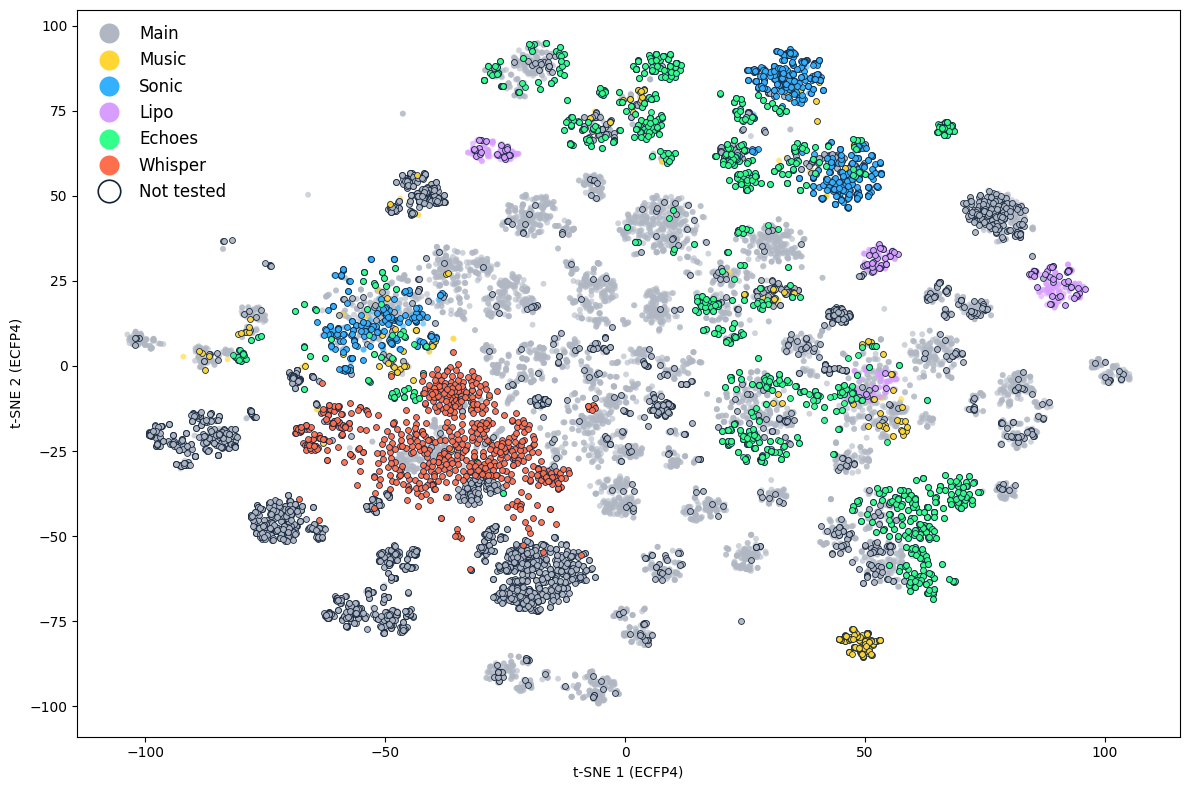

In [ ]:
## to-redo
import matplotlib.pyplot as plt
import matplotlib.lines as mlines

palette = {
    "Main": "#B0B7C3",
    "Music": "#FFD633",
    "Sonic": "#33B1FF",
    "Lipo": "#D89EFF",
    "Echoes": "#33FF8B",
    "Whisper": "#FF6F4D",
}

fig, ax = plt.subplots(figsize=(12, 8))

# pass 1: tested points, across all flavors — background layer
for flavor, color in palette.items():
    tested = df[(df["Lib Flavor"] == flavor) & (df["is_tested_in_Px"])]
    ax.scatter(tested["TSNE1"], tested["TSNE2"], s=18,
               facecolors=color, edgecolors="none",
               alpha=0.6, zorder=2)

# pass 2: untested points, across all flavors — solid ring, drawn on top
for flavor, color in palette.items():
    untested = df[(df["Lib Flavor"] == flavor) & (~df["is_tested_in_Px"])]
    ax.scatter(untested["TSNE1"], untested["TSNE2"], s=18,
               facecolors=color, edgecolors="#12233A", linewidths=0.6,
               alpha=0.95, zorder=3)

flavor_handles = [
    mlines.Line2D([], [], marker="o", linestyle="none",
                  markerfacecolor=color, markeredgecolor="none",
                  markersize=8, label=flavor)
    for flavor, color in palette.items()
]
outline_handle = mlines.Line2D([], [], marker="o", linestyle="none",
                                 markerfacecolor="white", markeredgecolor="#12233A",
                                 markeredgewidth=1.2, markersize=9, label="Not tested")

ax.set_xlabel("t-SNE 1 (ECFP4)")
ax.set_ylabel("t-SNE 2 (ECFP4)")
#ax.set_title("Chemical Space by Lib Flavor", fontsize=12, color="#12233A", pad=12,)

ax.legend(
    handles=flavor_handles + [outline_handle],
    title="", frameon=False, loc="upper left",
    markerscale=1.8, fontsize=12,
)

plt.tight_layout()
plt.show()

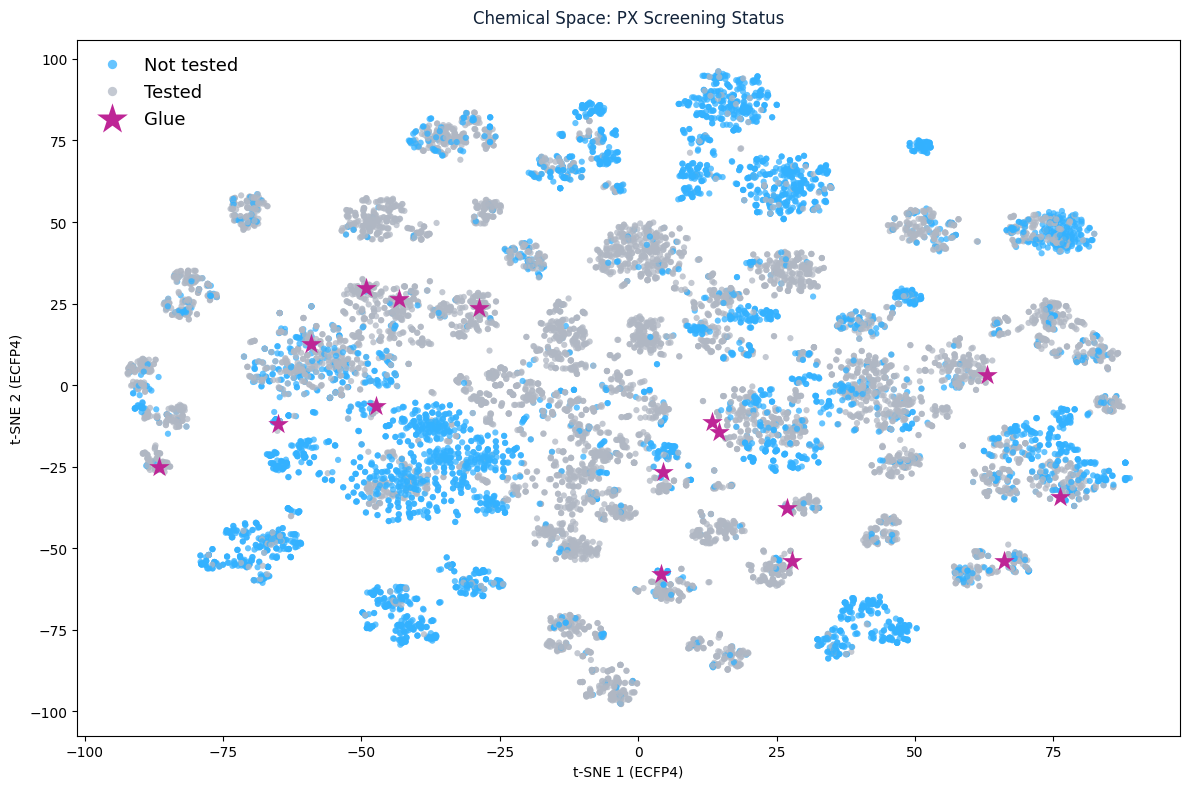

In [ ]:
## show glues on Tsne:
palette = {
    "Tested": "#B0B7C3",     # grey
    "Not tested": "#33B1FF", # green
}

df["PX_label"] = df["is_tested_in_Px"].map({True: "Tested", False: "Not tested"})

fig, ax = plt.subplots(figsize=(12, 8))

sns.scatterplot(
    data=df, x="TSNE1", y="TSNE2", hue="PX_label",
    palette=palette, s=20, alpha=0.75, linewidth=0, ax=ax,
)

glue = df[df["is_glue"]]
ax.scatter(glue["TSNE1"], glue["TSNE2"], s=240, marker="*", color="#be2596",
           linewidths=0, zorder=6, label="Glue")

ax.set_xlabel("t-SNE 1 (ECFP4)")
ax.set_ylabel("t-SNE 2 (ECFP4)")
ax.set_title(
    "Chemical Space: PX Screening Status",
    fontsize=12, color="#12233A", pad=12,
)

handles, labels = ax.get_legend_handles_labels()
ax.legend(
    handles, labels, title="", frameon=False,
    loc="upper left", markerscale=1.5, fontsize=13,
)

plt.tight_layout()
plt.show()

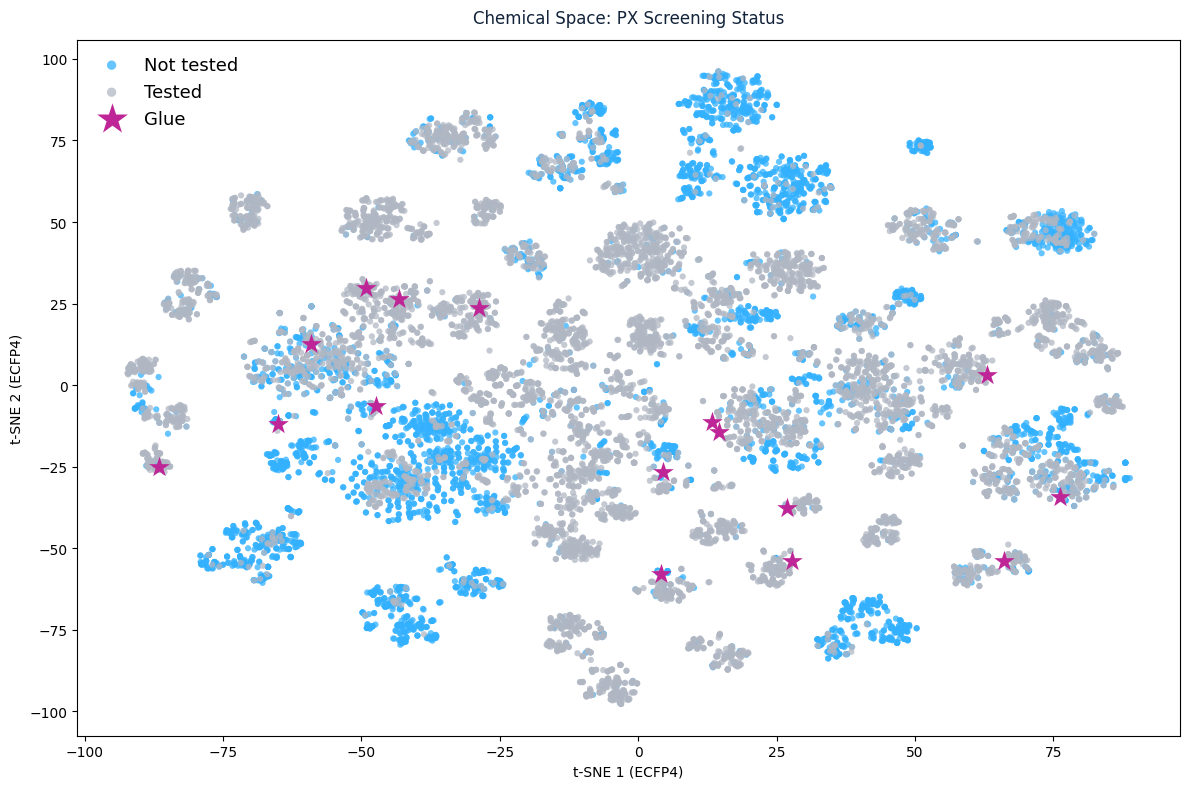

In [15]:
import matplotlib.pyplot as plt

palette = {
    "Tested": "#B0B7C3",
    "Not tested": "#33B1FF",
}

fig, ax = plt.subplots(figsize=(12, 8))

# pass 1: not tested — background
not_tested = df[~df["is_tested_in_Px"]]
ax.scatter(not_tested["TSNE1"], not_tested["TSNE2"], s=20,
           facecolors=palette["Not tested"], edgecolors="none",
           alpha=0.75, zorder=2, label="Not tested")

# pass 2: tested — drawn on top
tested = df[df["is_tested_in_Px"]]
ax.scatter(tested["TSNE1"], tested["TSNE2"], s=20,
           facecolors=palette["Tested"], edgecolors="none",
           alpha=0.75, zorder=3, label="Tested")

# glue compounds — highest layer
glue = df[df["is_glue"]]
ax.scatter(glue["TSNE1"], glue["TSNE2"], s=240, marker="*", color="#be2596",
           linewidths=0, zorder=6, label="Glue")

ax.set_xlabel("t-SNE 1 (ECFP4)")
ax.set_ylabel("t-SNE 2 (ECFP4)")
ax.set_title("Chemical Space: PX Screening Status", fontsize=12, color="#12233A", pad=12)

handles, labels = ax.get_legend_handles_labels()
ax.legend(handles, labels, title="", frameon=False, loc="upper left", markerscale=1.5, fontsize=13)
plt.tight_layout()
plt.show()

In [ ]:
#### Plot Similarity to known silent

In [ ]:
def add_nn_to_silent(df_query, df_ref=None, fp_col='ECFP4', id_col='Batch Molecule-Batch ID',
                     out_col='nn_sim_silent'):
    """For each df_query cpnd, the nearest analog in df_ref (default df_silent).
    Adds `out_col` (Tanimoto to that closest analog) + `<out_col>_id` (its ID).
    A cpnd is never paired with itself, so df_query and df_ref may overlap."""
    df_ref = df_silent if df_ref is None else df_ref
    ref = df_ref[df_ref[fp_col].notna()]
    ref_fps, ref_ids = list(ref[fp_col]), ref[id_col].to_numpy()

    sims, ids = [], []
    for qid, fp in zip(df_query[id_col], df_query[fp_col]):
        if fp is None:
            sims.append(np.nan)
            ids.append("")
            continue
        s = np.array(DataStructs.BulkTanimotoSimilarity(fp, ref_fps))
        s[ref_ids == qid] = -1                      # skip self-match
        i = int(s.argmax())
        sims.append(round(float(s[i]), 3))
        ids.append(ref_ids[i])

    out = df_query.copy()
    out[out_col] = sims
    out[f'{out_col}_id'] = ids
    return out

In [ ]:
df = apply_in_parallel(df, get_ecfp4_from_mol, 'ROMol', 'ECFP4', 4)

In [ ]:
main_df = df[df['Lib Flavor'] == 'Main']
sonic_df = df[df['Lib Flavor'] == 'Sonic']
music_df = df[df['Lib Flavor'] == 'Music']
lipo_df = df[df['Lib Flavor'] == 'Lipo']
echoes_df = df[df['Lib Flavor'] == 'Echoes']
df_silent = df[df['is_silent'] == True]

lipo_df = add_nn_to_silent(lipo_df)
main_df = add_nn_to_silent(main_df)
sonic_df = add_nn_to_silent(sonic_df)
music_df = add_nn_to_silent(music_df)
echoes_df = add_nn_to_silent(echoes_df)

flavors = {'Main': main_df, 'Sonic': sonic_df, 'Music': music_df, 'Lipo': lipo_df, 'Echoes': echoes_df}
pd.DataFrame([{'flavor': k,
               'n': len(v),
               'mean': round(v['nn_sim_silent'].mean(), 3),
               'min': v['nn_sim_silent'].min(),
               'max': v['nn_sim_silent'].max(),
               'n >= 0.75': int((v['nn_sim_silent'] >= 0.75).sum()),
               '% >= 0.75': round(100 * (v['nn_sim_silent'] >= 0.75).mean(), 1)}
              for k, v in flavors.items()]).set_index('flavor')

In [ ]:
palette = {
    "Main": "#B0B7C3",
    "Music": "#FFD633",
    "Sonic": "#33B1FF",
    "Lipo": "#D89EFF",
    "Echoes": "#33FF8B",  # the compatible grey from before
}
flavors = {"Main": main_df, "Sonic": sonic_df, "Music": music_df, "Lipo": lipo_df, 'Echoes': echoes_df}

combined = pd.concat(
    [v.assign(**{"Lib Flavor": k}) for k, v in flavors.items()],
    ignore_index=True,
)

sns.set_theme(style="white", font_scale=1.35)
fig, ax = plt.subplots(figsize=(8, 6), dpi=150)

sns.kdeplot(
    data=combined, x="nn_sim_silent", hue="Lib Flavor",
    palette=palette, fill=True, common_norm=False,
    alpha=0.35, linewidth=1.8, ax=ax,
)

# reference line at the 0.75 threshold used in your summary table
ax.axvline(0.75, color="#ea5929", linestyle="--", linewidth=1, alpha=0.6)
ax.text(0.755, ax.get_ylim()[1] * 0.95, "0.75", fontsize=8.5, color="#ea5929")

ax.set_xlabel("Tanimoto similarity (ECFP4) to nearest silent compound")
ax.set_ylabel("Density")
ax.set_title(
    "How similar is each library to known silent compounds?",
    fontsize=15, color="#12233A", pad=12,
)
sns.despine(left=True)
ax.yaxis.grid(True, linewidth=0.5, color="#E6E9ED")
ax.set_axisbelow(True)
ax.set_xlim(0.4, 1.0)

sns.move_legend(ax, "upper right", frameon=False, title="")

plt.tight_layout()
plt.show()

In [ ]:
ratios = pd.DataFrame([
    {
        "flavor": k,
        "n_lib": len(v),
        "n_tested": int(v["is_tested_in_Px"].sum()),
        "n_silent": int(v["is_silent"].sum()),
        "ratio_silent": round(v["is_silent"].sum() / v["is_tested_in_Px"].sum(), 3)
                        if v["is_tested_in_Px"].sum() > 0 else None,
        "pct_silent": round(100 * v["is_silent"].sum() / v["is_tested_in_Px"].sum(), 1)
                      if v["is_tested_in_Px"].sum() > 0 else None,
    }
    for k, v in flavors.items()
]).set_index("flavor")

ratios